In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv("/content/Churn_Modelling.csv")

In [3]:
df


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [5]:
print(df["Exited"].value_counts())

Exited
0    7963
1    2037
Name: count, dtype: int64


In [6]:
churn_rate = df["Exited"].mean() * 100
print(churn_rate)

20.369999999999997


In [7]:
print(f"customer churn rate : {churn_rate:.2f}%")

customer churn rate : 20.37%


In [8]:
churn_count = df["Exited"].map({
    0: "stayed",
    1: "Exited"
}).value_counts()

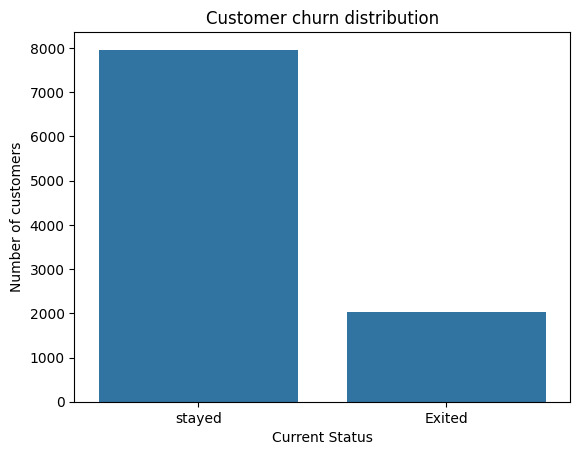

In [9]:
sns.barplot(x = churn_count.index, y = churn_count.values)

plt.title("Customer churn distribution")
plt.xlabel("Current Status")
plt.ylabel("Number of customers")
plt.show()

CHURN ANALYSIS BY AGE GROUP

In [10]:
df["agegroup"] = pd.cut(
    df["Age"],
    bins = [0,25,35,45,55,65,100],
    labels = ["18-25",
              "26-35",
              "36-45",
              "46-55",
              "56-65",
              "66+"
              ]
)

In [11]:
age_churn = df.groupby(
    "agegroup",
    observed= False
)["Exited"].mean() *100

print(f"churn rate by age group: {age_churn.round(2)}")

churn rate by age group: agegroup
18-25     7.53
26-35     8.50
36-45    19.62
46-55    50.57
56-65    48.32
66+      13.26
Name: Exited, dtype: float64


CHURN ANALYSIS BY GENDER

In [12]:
gender_churn = df.groupby("Gender")["Exited"].mean()*100

print(f"Churn rate by gender: {gender_churn.round(2)}")

Churn rate by gender: Gender
Female    25.07
Male      16.46
Name: Exited, dtype: float64


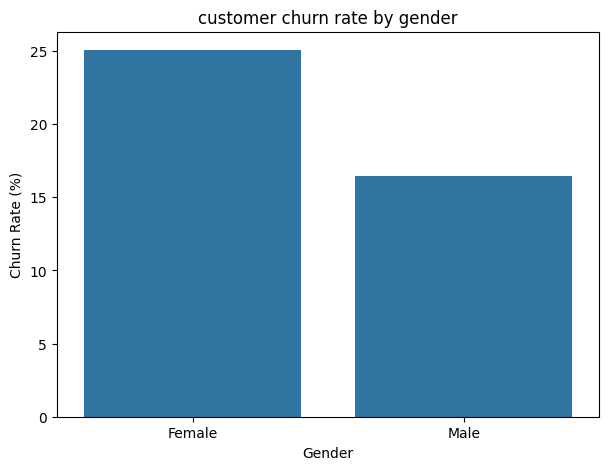

In [13]:
plt.figure(figsize=(7,5))
sns.barplot(x = gender_churn.index, y = gender_churn.values)
plt.title("customer churn rate by gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.show()

In [14]:
print(f"churn rate by gender {gender_churn.round(2)}")
print("------------------------------------------------")
print(f"Customer count by gender {df["Gender"].value_counts()}")
print("------------------------------------------------")
print(f"Customers who exited by gender {df[df["Exited"] == 1]["Gender"].value_counts()}")

churn rate by gender Gender
Female    25.07
Male      16.46
Name: Exited, dtype: float64
------------------------------------------------
Customer count by gender Gender
Male      5457
Female    4543
Name: count, dtype: int64
------------------------------------------------
Customers who exited by gender Gender
Female    1139
Male       898
Name: count, dtype: int64


CHURN ANALYSIS BY GEOGRAPHY

In [15]:
geo_churn = df.groupby("Geography")["Exited"].mean() * 100
print(f"Churn rate by geography: {geo_churn.round(2)}")

Churn rate by geography: Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64


Text(0, 0.5, 'CHurn rate (%)')

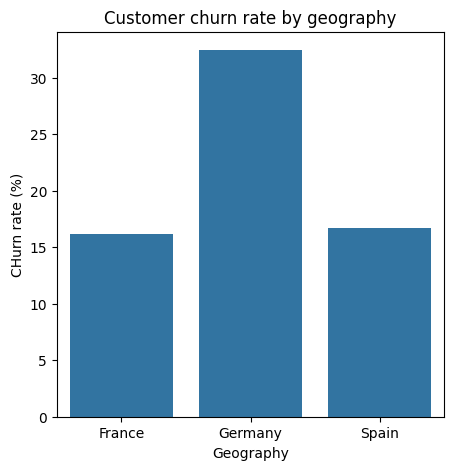

In [16]:
plt.figure(figsize = (5,5))

sns.barplot(x = geo_churn.index, y = geo_churn.values)

plt.title("Customer churn rate by geography")
plt.xlabel("Geography")
plt.ylabel("CHurn rate (%)")


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   RowNumber        10000 non-null  int64   
 1   CustomerId       10000 non-null  int64   
 2   Surname          10000 non-null  object  
 3   CreditScore      10000 non-null  int64   
 4   Geography        10000 non-null  object  
 5   Gender           10000 non-null  object  
 6   Age              10000 non-null  int64   
 7   Tenure           10000 non-null  int64   
 8   Balance          10000 non-null  float64 
 9   NumOfProducts    10000 non-null  int64   
 10  HasCrCard        10000 non-null  int64   
 11  IsActiveMember   10000 non-null  int64   
 12  EstimatedSalary  10000 non-null  float64 
 13  Exited           10000 non-null  int64   
 14  agegroup         10000 non-null  category
dtypes: category(1), float64(2), int64(9), object(3)
memory usage: 1.1+ MB


CHURN ANALYSIS BY NUMBER OF BANK PRODUCTS

In [18]:
product_churn = df.groupby("NumOfProducts")["Exited"].mean() *100

print(f"Customer churn rate by product: {product_churn.round(2)}")

Customer churn rate by product: NumOfProducts
1     27.71
2      7.58
3     82.71
4    100.00
Name: Exited, dtype: float64


Text(0, 0.5, 'Churn Rate (%)')

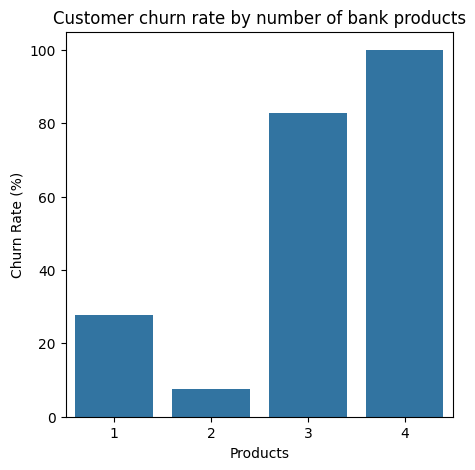

In [19]:
plt.figure(figsize=(5,5))

sns.barplot(x = product_churn.index, y = product_churn.values)
plt.title("Customer churn rate by number of bank products")
plt.xlabel("Products")
plt.ylabel("Churn Rate (%)")

In [20]:
df["NumOfProducts"].value_counts()

,count
NumOfProducts,
1,5084
2,4590
3,266
4,60


In [21]:
print("Customer churn by number of products")
df["NumOfProducts"].value_counts().sort_index()



Customer churn by number of products


,count
NumOfProducts,
1,5084
2,4590
3,266
4,60


In [22]:
print("\nchurn Status by Number of products\n\n")

print(pd.crosstab(
    df["NumOfProducts"],
    df["Exited"],
    margins= True
)
)



churn Status by Number of products


Exited            0     1    All
NumOfProducts                   
1              3675  1409   5084
2              4242   348   4590
3                46   220    266
4                 0    60     60
All            7963  2037  10000


CHURN ANALYSIS BY ACTIVE MEMBERSHIP


In [25]:
activity_churn = df.groupby("IsActiveMember")["Exited"].mean() *100

print(f"Churn rate by Active member {activity_churn.round(2)}")

Churn rate by Active member IsActiveMember
0    26.85
1    14.27
Name: Exited, dtype: float64


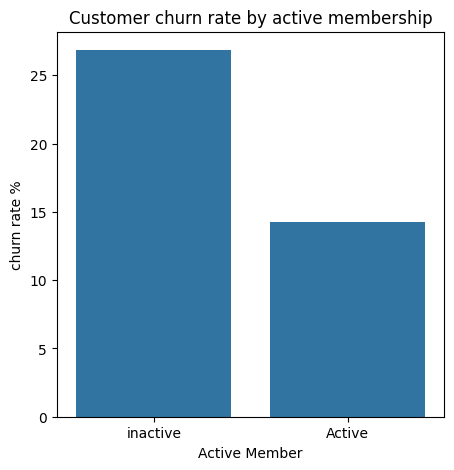

In [26]:
plt.figure(figsize=(5,5))

sns.barplot(x = activity_churn.index , y = activity_churn.values)

plt.title("Customer churn rate by active membership")
plt.xlabel("Active Member")
plt.ylabel("churn rate %")

plt.xticks([0,1], ["inactive", "Active"])
plt.show()

CHURN ANALYSIS BY TENURE

In [28]:
tenure_churn = df.groupby("Tenure")["Exited"].mean() * 100

print("Customer churn rate by Tenure", tenure_churn.round(2))

Customer churn rate by Tenure Tenure
0     23.00
1     22.42
2     19.18
3     21.11
4     20.53
5     20.65
6     20.27
7     17.22
8     19.22
9     21.65
10    20.61
Name: Exited, dtype: float64


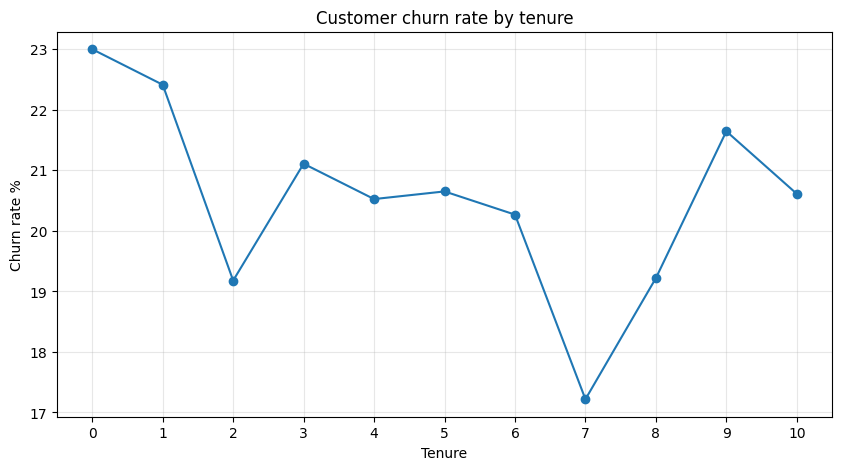

In [31]:
plt.figure(figsize=(10,5))

plt.plot(tenure_churn.index, tenure_churn.values, marker = "o")

plt.title("Customer churn rate by tenure")
plt.xlabel("Tenure")
plt.ylabel("Churn rate %")

plt.xticks(range(0,11))
plt.grid(True, alpha = 0.3)

plt.show()

CHURN ANALYSIS BY CREDIT SCORE

In [35]:
df["creditscore_group"] = pd.cut(
    df["CreditScore"],
    bins = [0,580,670,740,800,1000],
    labels = [
        "poor",
        "fair",
        "good",
        "very Good",
        "Exelent"
    ],
    include_lowest= True
)

credit_churn = df.groupby("creditscore_group", observed= False)["Exited"].mean() *100

print("Churn rate by credit score",credit_churn.round(2))

Churn rate by credit score creditscore_group
poor         22.15
fair         20.39
good         18.82
very Good    20.25
Exelent      19.69
Name: Exited, dtype: float64


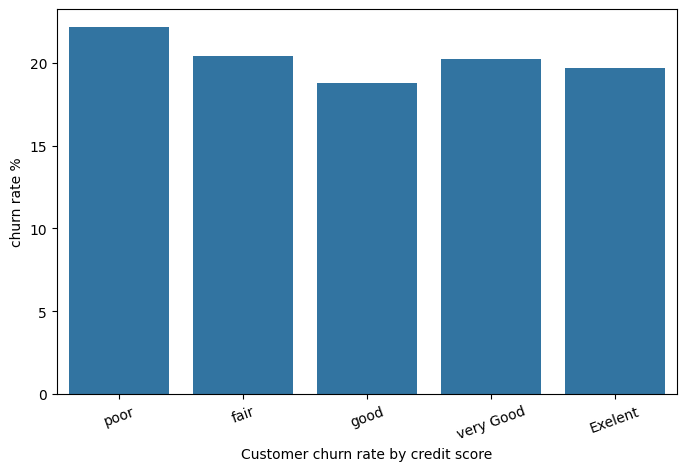

In [38]:
plt.figure(figsize=(8,5))

sns.barplot(x = credit_churn.index.astype(str), y = credit_churn.values)

plt.xlabel("Customer churn rate by credit score")
plt.ylabel("churn rate %")
plt.xticks(rotation = 20)

plt.show()

CHURN ANALYSIS BY ACCOUNT BALANCE

In [48]:
df["balancegroup"] = pd.qcut(
    df["Balance"],
    q = 5,
    duplicates= "drop"
)

balance_churn = df.groupby("balancegroup", observed= False)["Exited"].mean()*100

print(f"customer curn rate by account balance {balance_churn.round(2)}")

customer curn rate by account balance balancegroup
(-0.001, 73080.908]         14.75
(73080.908, 110138.926]     22.30
(110138.926, 133710.358]    26.95
(133710.358, 250898.09]     23.10
Name: Exited, dtype: float64


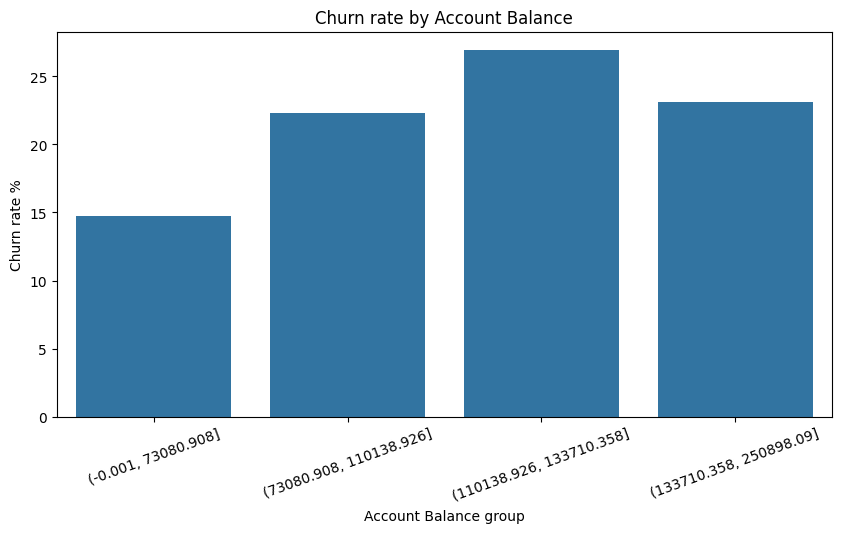

In [49]:
plt.figure(figsize =(10,5))

sns.barplot(x = balance_churn.index.astype(str), y = balance_churn.values)

plt.title("Churn rate by Account Balance")
plt.xlabel("Account Balance group")
plt.ylabel("Churn rate %")
plt.xticks(rotation= 20)
plt.show()

CHURN ANALYSIS BY CREDIT CARD

In [50]:
# Calculate churn rate by credit card ownership
card_churn = df.groupby("HasCrCard")["Exited"].mean() * 100

print("Churn rate by credit card ownership:")
print(card_churn.round(2))

Churn rate by credit card ownership:
HasCrCard
0    20.81
1    20.18
Name: Exited, dtype: float64


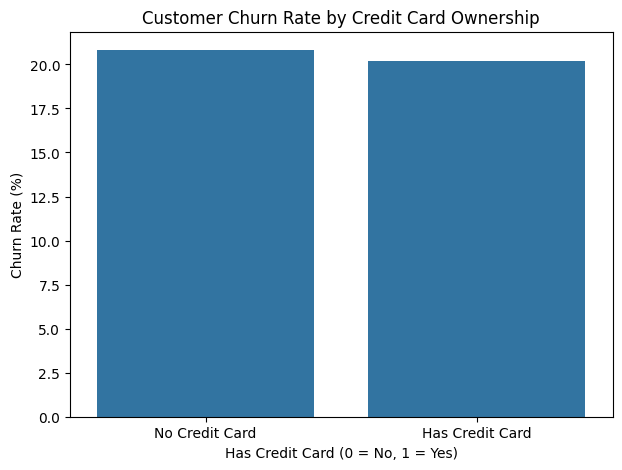

In [51]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=card_churn.index,
    y=card_churn.values
)

plt.title("Customer Churn Rate by Credit Card Ownership")
plt.xlabel("Has Credit Card (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.xticks([0, 1], ["No Credit Card", "Has Credit Card"])

plt.show()

In [52]:
# Divide customers into five salary groups
df["SalaryGroup"] = pd.qcut(
    df["EstimatedSalary"],
    q=5,
    duplicates="drop"
)

# Calculate churn rate by salary group
salary_churn = (
    df.groupby("SalaryGroup", observed=False)["Exited"]
    .mean() * 100
)

print("Churn rate by estimated salary:")
print(salary_churn.round(2))

Churn rate by estimated salary:
SalaryGroup
(11.579, 41050.736]         19.95
(41050.736, 80238.34]       19.95
(80238.34, 119710.038]      20.20
(119710.038, 159836.726]    20.20
(159836.726, 199992.48]     21.55
Name: Exited, dtype: float64


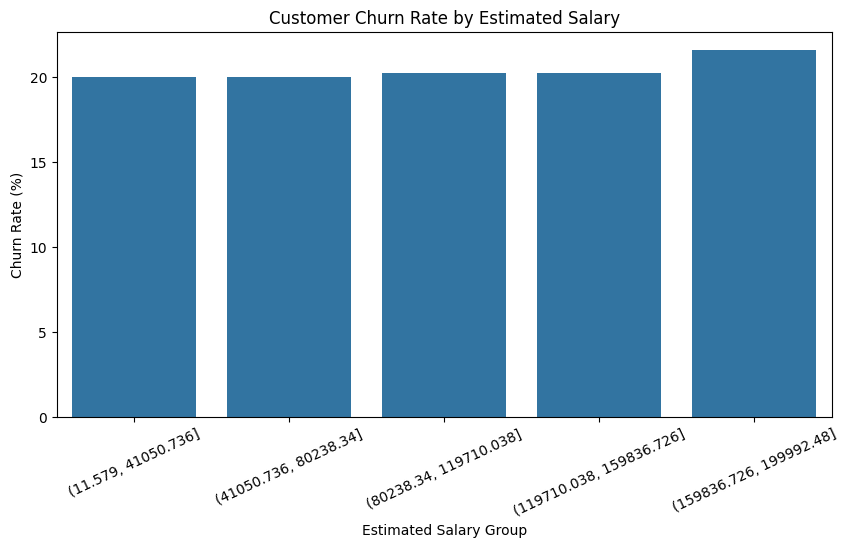

In [53]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=salary_churn.index.astype(str),
    y=salary_churn.values
)

plt.title("Customer Churn Rate by Estimated Salary")
plt.xlabel("Estimated Salary Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25)

plt.show()